## 연습문제 풀이: 학습 조건 바꾸기

### 바꿀 수 있는 하이퍼파라미터

| 항목 | 코드의 이름 | 바뀌는 내용 |
| --- | --- | --- |
| 은닉층 뉴런 수 | `hidden_size` | 은닉층에서 계산하는 값의 개수 |
| 에포크 수 | `epochs` | 전체 학습 데이터를 반복해서 사용하는 횟수 |
| 학습률 | `lr` | 한 번에 가중치와 편향을 갱신하는 크기의 기준 |
| 배치 크기 | `batch_size` | 한 번의 갱신에 사용하는 이미지 수 |

은닉층 수, 활성화 함수, 옵티마이저 종류도 바꿀 수 있다.


In [1]:
from copy import deepcopy

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42


### 데이터 준비


In [2]:
digits = load_digits()
X, y = digits.data, digits.target

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)  # stratify: 클래스 비율 유지
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED)

train_inputs = torch.tensor(X_train / 16.0, dtype=torch.float32)  # 픽셀을 0~1 범위의 실수 텐서로 변환
val_inputs = torch.tensor(X_val / 16.0, dtype=torch.float32)
test_inputs = torch.tensor(X_test / 16.0, dtype=torch.float32)
train_labels = torch.tensor(y_train, dtype=torch.long)  # 분류 정답은 정수 클래스 번호
val_labels = torch.tensor(y_val, dtype=torch.long)
test_labels = torch.tensor(y_test, dtype=torch.long)
print("학습·검증·테스트:", len(train_labels), len(val_labels), len(test_labels))

train_dataset = TensorDataset(train_inputs, train_labels)


학습·검증·테스트: 1077 360 360


### 모델과 학습 함수


In [3]:
def make_model(hidden_size=32):
    return nn.Sequential(
        nn.Linear(64, hidden_size),
        nn.ReLU(),
        nn.Linear(hidden_size, 10),
    )

criterion = nn.CrossEntropyLoss()


In [4]:
def evaluate(model, inputs, labels):
    model.eval()  # 평가 모드
    with torch.no_grad():  # 현재 가중치로 예측만 계산한다.
        scores = model(inputs)  # 이미지별 클래스 점수, (이미지 수, 10)
        loss_value = criterion(scores, labels).item()
        # 클래스 축(dim=1)에서 가장 큰 점수의 위치를 고르고, 정답 여부를 1·0으로 바꿔 평균한다.
        accuracy = (scores.argmax(dim=1) == labels).float().mean().item()
    return loss_value, accuracy  # 평균 손실과 정확도를 반환한다.


In [5]:
def fit(model, optimizer, loader, epochs=20):
    history = []
    best_loss = float("inf")
    best_state = deepcopy(model.state_dict())  # 파라미터를 이후 갱신의 영향을 받지 않는 복사본으로 보관한다.
    for epoch in range(epochs):
        model.train()
        for inputs, labels in loader:  # 한 배치씩 가중치를 갱신하며 모든 학습 데이터를 사용한다.
            loss = criterion(model(inputs), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        # 한 에포크가 끝난 시점의 모델로 학습·검증 결과를 기록한다.
        train_loss, train_accuracy = evaluate(model, train_inputs, train_labels)
        val_loss, val_accuracy = evaluate(model, val_inputs, val_labels)
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss,
                        "train_accuracy": train_accuracy, "val_accuracy": val_accuracy})
        if val_loss < best_loss:  # 검증 손실이 가장 작았던 시점의 파라미터를 보관한다.
            best_loss = val_loss
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)  # 선택한 시점의 가중치와 편향을 모델에 복원한다.
    return pd.DataFrame(history)  # 에포크별 손실·정확도를 표로 반환한다.


## 학습 조건 비교

기준 조건에서 한 항목씩 바꾼다. 각 실험은 모델·옵티마이저·배치 생성기를 새로 만들고 같은 난수 시드에서 시작한다. 데이터 분할과 전처리는 모두 같다. 은닉층은 하나, 활성화 함수는 ReLU, 옵티마이저는 Adam으로 유지한다.

| 항목 | 기준값 | 비교할 값 |
| --- | --- | --- |
| 은닉층 뉴런 수 | 32 | 16, 64, 128 |
| 에포크 수 | 20 | 5, 50, 100 |
| 학습률 | 0.001 | 0.0001, 0.01 |
| 배치 크기 | 32 | 16, 128 |

각 실험에서는 검증 손실이 가장 작았던 에포크의 모델을 사용한다. 비교 표의 손실과 정확도도 이 시점의 값이다.


In [6]:
base = {"hidden_size": 32, "epochs": 20, "lr": 0.001, "batch_size": 32}
experiments = {"baseline": base.copy()}
changes = {
    "hidden_size": [16, 64, 128],
    "epochs": [5, 50, 100],
    "lr": [0.0001, 0.01],
    "batch_size": [16, 128],
}

for parameter, values in changes.items():
    for value in values:
        settings = base.copy()
        settings[parameter] = value  # 기준 조건에서 이 항목만 변경한다.
        experiments[f"{parameter}={value}"] = settings

display(pd.DataFrame(experiments).T)


,hidden_size,epochs,lr,batch_size
baseline,32.0,20.0,0.0010,32.0
hidden_size=16,16.0,20.0,0.0010,32.0
hidden_size=64,64.0,20.0,0.0010,32.0
hidden_size=128,128.0,20.0,0.0010,32.0
epochs=5,32.0,5.0,0.0010,32.0
epochs=50,32.0,50.0,0.0010,32.0
epochs=100,32.0,100.0,0.0010,32.0
lr=0.0001,32.0,20.0,0.0001,32.0
lr=0.01,32.0,20.0,0.0100,32.0
batch_size=16,32.0,20.0,0.0010,16.0


In [7]:
models = {}
histories = {}
results = []

for name, settings in experiments.items():
    torch.manual_seed(SEED)
    model = make_model(hidden_size=settings["hidden_size"])
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["lr"])
    loader = DataLoader(
        train_dataset, batch_size=settings["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    history = fit(model, optimizer, loader, epochs=settings["epochs"])
    train_loss, train_accuracy = evaluate(model, train_inputs, train_labels)
    val_loss, val_accuracy = evaluate(model, val_inputs, val_labels)
    best_epoch = int(history.loc[history.val_loss.idxmin(), "epoch"])

    models[name] = model
    histories[name] = history
    results.append({
        "experiment": name,
        "best_epoch": best_epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
    })

comparison = pd.DataFrame(results).set_index("experiment")
display(comparison.round(4))


,best_epoch,train_loss,val_loss,train_accuracy,val_accuracy
experiment,,,,,
baseline,20,0.2322,0.2765,0.9508,0.9278
hidden_size=16,20,0.3640,0.4171,0.9415,0.9278
hidden_size=64,20,0.1561,0.2064,0.9712,0.9444
hidden_size=128,19,0.1083,0.1565,0.9786,0.9528
epochs=5,5,1.1773,1.1943,0.8589,0.8417
epochs=50,50,0.0915,0.1414,0.9824,0.9667
epochs=100,100,0.0373,0.1035,0.9981,0.9639
lr=0.0001,20,1.9319,1.9303,0.7614,0.7611
lr=0.01,19,0.0269,0.1047,0.9972,0.9667


### 조건별 검증 결과

각 그래프에서 기준 조건과 한 항목만 바꾼 실험을 비교한다. 곡선은 모델을 복원하기 전까지의 모든 에포크 기록이다. 배치 크기를 바꾸면 한 에포크 안에서 가중치를 갱신하는 횟수도 달라진다.

에포크 수만 바꾼 실험은 같은 초기 상태와 배치 순서로 학습하므로 공통 구간의 곡선이 겹친다. 끝점은 각 실험에서 학습을 마친 에포크를 나타낸다.


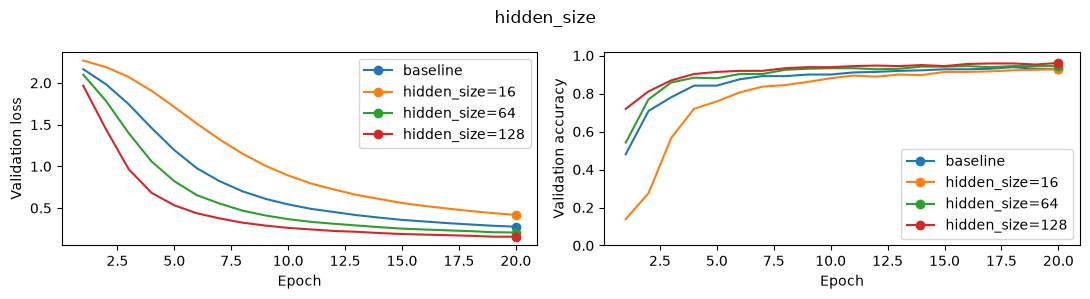

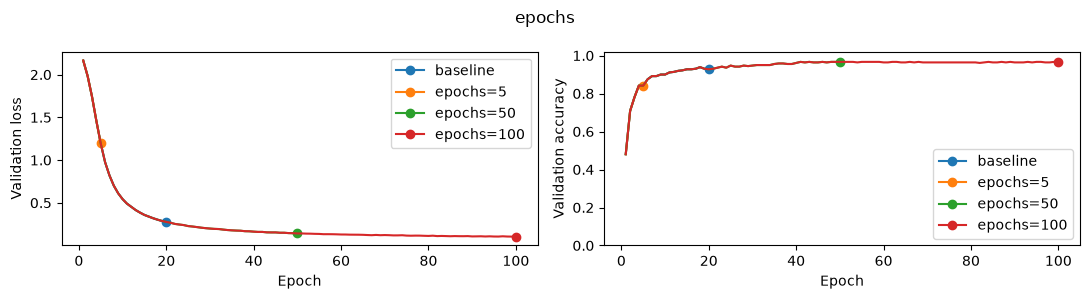

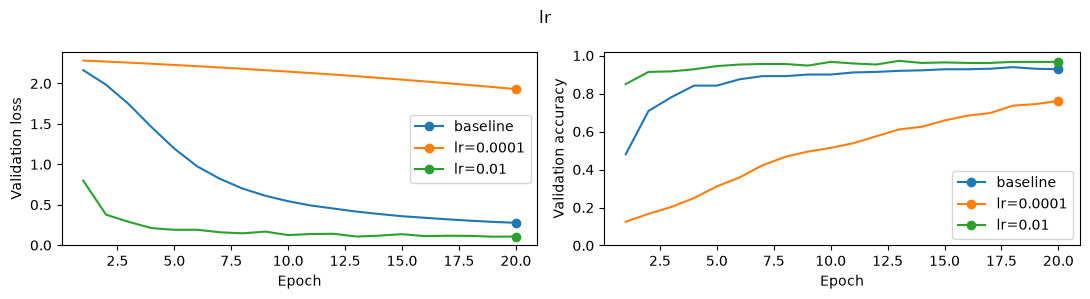

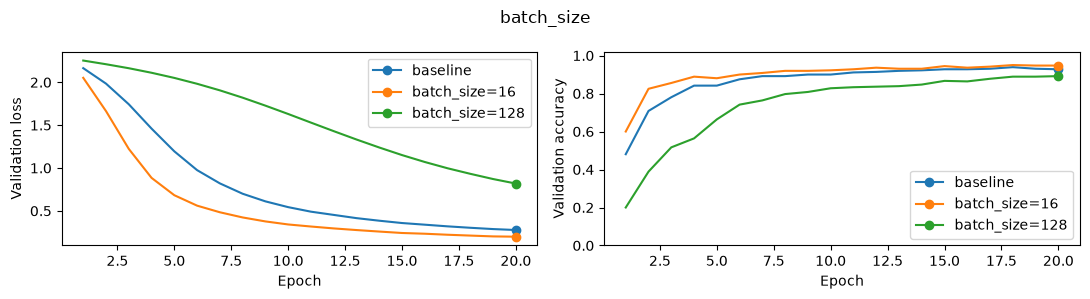

In [8]:
for parameter, values in changes.items():
    names = ["baseline"] + [f"{parameter}={value}" for value in values]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    # 곡선 끝의 점은 각 실험의 마지막 에포크를 표시한다.
    for name in names:
        history = histories[name]
        axes[0].plot(history["epoch"], history["val_loss"], label=name, marker="o", markevery=[-1])
        axes[1].plot(history["epoch"], history["val_accuracy"], label=name, marker="o", markevery=[-1])
    axes[0].set(xlabel="Epoch", ylabel="Validation loss")
    axes[1].set(xlabel="Epoch", ylabel="Validation accuracy", ylim=(0, 1.02))
    for ax in axes:
        ax.legend()
    fig.suptitle(parameter)
    plt.tight_layout()
    plt.show()


### 실험 결과 해석

| 바꾼 항목 | 실행 결과와 해석 |
| --- | --- |
| 은닉층 뉴런 수 | 16개와 32개는 정확도가 같았지만, 32개의 손실이 더 작았다. 64개와 128개에서는 정확도도 높아졌다. |
| 에포크 수 | 50회에서 100회로 늘리면 검증 손실은 줄었지만, 맞힌 이미지 수는 한 장 줄었다. |
| 학습률 | 0.0001은 20에포크 동안 학습이 느리게 진행됐다. 0.01은 기준 조건보다 낮은 검증 손실과 높은 정확도를 얻었다. |
| 배치 크기 | 16장의 검증 정확도가 128장보다 높았다. 한 에포크의 갱신 횟수는 각각 68회와 9회이므로, 갱신 횟수의 영향도 함께 고려해야 한다. |


### 모델 선택과 학습 곡선

실험 간 비교에도 검증 손실을 사용해 모델 하나를 선택한다. 기준 조건과 선택한 조건의 학습·검증 곡선을 함께 확인한다.


선택한 조건: epochs=100
선택한 에포크: 100


,best_epoch,train_loss,val_loss,train_accuracy,val_accuracy
experiment,,,,,
baseline,20,0.2322,0.2765,0.9508,0.9278
epochs=100,100,0.0373,0.1035,0.9981,0.9639


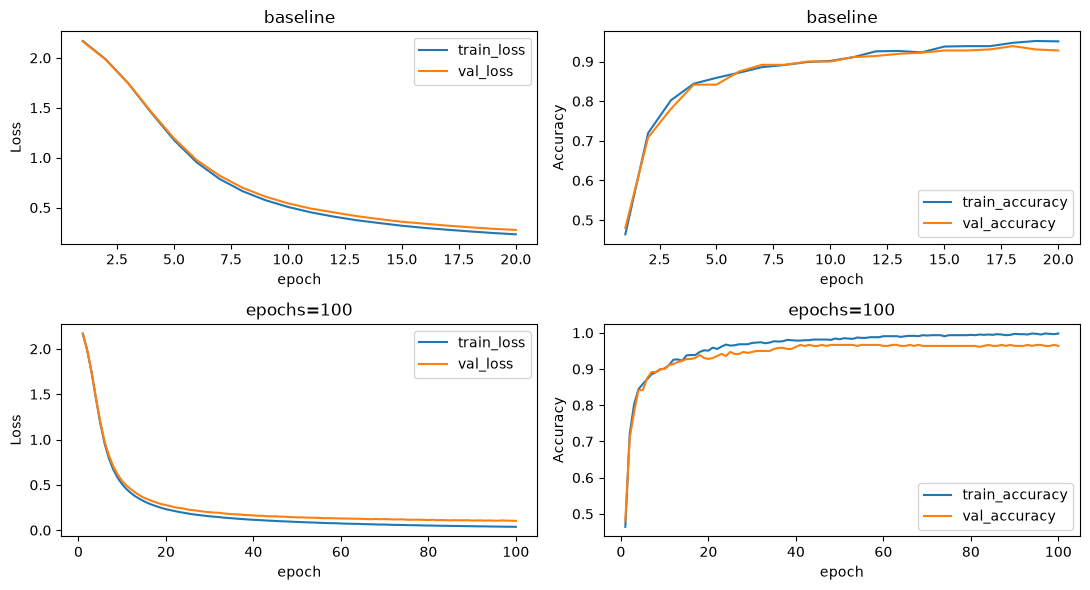

In [9]:
selected_name = comparison["val_loss"].idxmin()
selected_model = models[selected_name]
print("선택한 조건:", selected_name)
print("선택한 에포크:", int(comparison.loc[selected_name, "best_epoch"]))
display(comparison.loc[["baseline", selected_name]].round(4))

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, name in enumerate(["baseline", selected_name]):
    history = histories[name]
    history.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[row, 0], ylabel="Loss")
    history.plot(x="epoch", y=["train_accuracy", "val_accuracy"], ax=axes[row, 1], ylabel="Accuracy")
    for ax in axes[row]:
        ax.set_title(name)
plt.tight_layout()
plt.show()


### 테스트 정확도 확인

선택한 모델의 테스트 정확도를 한 번 확인한다.


In [10]:
_, test_accuracy = evaluate(selected_model, test_inputs, test_labels)
print(f"테스트 정확도: {test_accuracy:.2%}")


테스트 정확도: 95.83%


## 결과 종합

- 검증 손실을 기준으로 은닉층 뉴런 32개, 100에포크, 학습률 0.001, 배치 크기 32인 조건을 선택했다.
- 이번 결과는 한 항목씩 바꾼 비교다. 여러 설정을 함께 바꾼 조합의 결과는 별도로 확인해야 한다.
